In [1]:
"""Baseline simulation without external drives to develop baseline correction method."""

import os.path as op
import json
import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))

# The number of cores may need modifying depending on your current machine.
n_procs = 10

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/dipole.py:84: UserWarning: No external drives or biases loaded
  warnings.warn("No external drives or biases loaded", UserWarning)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Trial 1: 180.0 ms...
Trial 1: 190.0 ms...
Trial 1: 200.0 ms...
Trial 1: 210.0 ms...
Trial 1: 220.0 ms...
Trial 1: 230.0 ms...
Trial 1: 240.0 ms...
Trial 1: 250.0 ms...
Trial 1: 260.0 ms...
Trial 1: 270.0 ms...
Trial 1: 280.0 ms...
Trial 1: 290.0 ms...
Trial 1: 300.0 ms...
Trial 1: 310.0 ms...
Trial 1: 320.0 ms...
Trial 1: 330.0 ms...
Trial 1: 340.0 ms...
Trial 1: 350.0 ms...
Tr

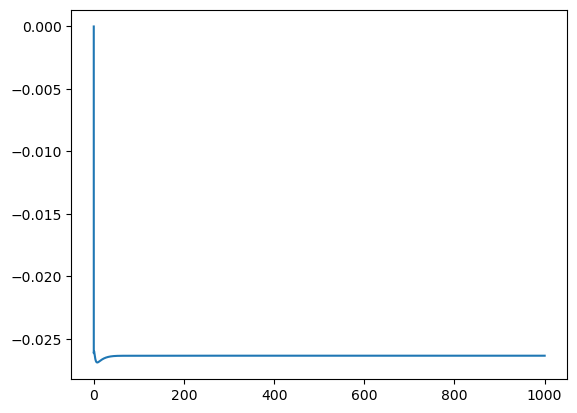

In [2]:

tstop = 1000


net_no_drives = duecker_ET_model()
net_no_drives.set_cell_positions(inplane_distance=30.)


#with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
dpl_net_no_drives = simulate_dipole(net_no_drives, tstop=tstop, n_trials=1, bsl_cor='none', record_vsec='all')[0]

plt.plot(dpl_net_no_drives.times,dpl_net_no_drives.data['agg'])

Text(0.5, 1.0, 'L5 pyramidal neuron')

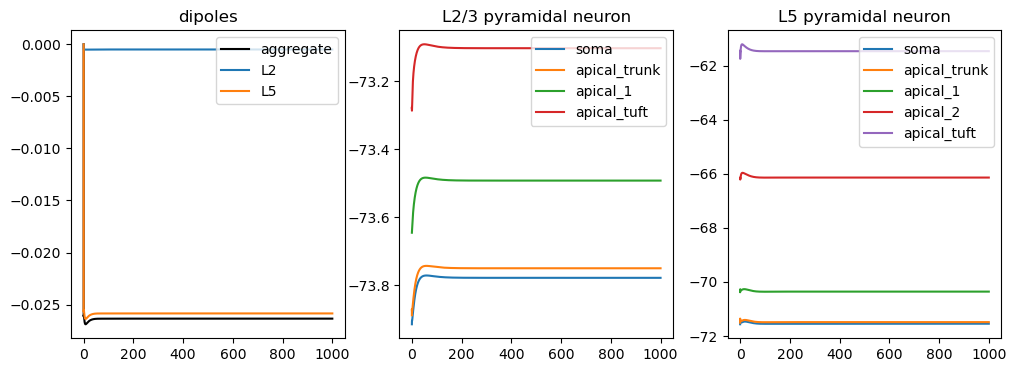

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['agg'], linewidth=1.5, color='k', label='aggregate')
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L2'], linewidth=1.5, label='L2')
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L5'], linewidth=1.5, label='L5')
ax[0].set_title('dipoles')
ax[0].legend(loc='upper right')
yticks = []
yticklabels = []
for s, section in enumerate(['soma', 'apical_trunk', 'apical_1', 'apical_tuft']):
    v_s = net_no_drives.cell_response.vsec[0][35][section]
    ax[1].plot(dpl_net_no_drives.times, np.array(v_s), label=section, linewidth=1.5)

ax[1].legend(loc='upper right')
ax[1].set_title('L2/3 pyramidal neuron')

yticks = []
yticklabels = []
prev_v = -80
for s, section in enumerate(['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']):
    v_s = net_no_drives.cell_response.vsec[0][170][section]
    ax[2].plot(dpl_net_no_drives.times, np.array(v_s), label=section, linewidth=1.5)
    yticklabels.append(np.round(np.min(np.array(v_s)),2))
    yticklabels.append(np.round(np.max(np.array(v_s)),2))

ax[2].legend(loc='upper right')
ax[2].set_title('L5 pyramidal neuron')

In [4]:
def exp_decay(t, A, C, b):
    
    return ((C-A) * np.exp(-b*(t))) + A

In [5]:
from scipy.optimize import curve_fit

In [6]:

bsl_dipole_ca = {'times': dpl_net_no_drives.times.tolist(),
                 'L2': dpl_net_no_drives.data['L2'].tolist(),
                 'L5': dpl_net_no_drives.data['L5'].tolist()}

A_L2 = bsl_dipole_ca['L2'][-1]
A_L5 = bsl_dipole_ca['L5'][-1]

C_L2 = bsl_dipole_ca['L2'][1]
C_L5 = bsl_dipole_ca['L5'][1]

def _exp_decay_wrapper_l2(t, b):
        return exp_decay(t, A_L2, C_L2, b)
def _exp_decay_wrapper_l5(t, b):
        return exp_decay(t, A_L5, C_L5, b)

popt_l2, pcov = curve_fit(_exp_decay_wrapper_l2, bsl_dipole_ca['times'][1:], bsl_dipole_ca['L2'][1:], p0=(0.01), bounds=(0, np.inf))                    # fit from second sample to avoid fitting an offset
popt_l5, pcov = curve_fit(_exp_decay_wrapper_l2, bsl_dipole_ca['times'][1:], bsl_dipole_ca['L5'][1:], p0=(0.01), bounds=(0, np.inf))

exp_fit_l2 = _exp_decay_wrapper_l2(np.array(bsl_dipole_ca['times']), *popt_l2)
exp_fit_l5 = _exp_decay_wrapper_l5(np.array(bsl_dipole_ca['times']), *popt_l5)

bsl_dipole_ca['popt_l2'] = list(popt_l2)
bsl_dipole_ca['popt_l5'] = list(popt_l5)

with open(op.join(hnn_core_root, 'param', 'bsl_dipole_dueckerET.json'), 'w') as f:
    json.dump(bsl_dipole_ca, f, indent=4, ensure_ascii=False)

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(12,3), constrained_layout=True, sharey=True)
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L2'])
ax[0].plot(dpl_net_no_drives.times, dpl_net_no_drives.data['L5'])
ax[0].set_title('Original dipoles')
ax[0].set_ylabel('Dipole (nA$\cdot$m)')
ax[1].plot(dpl_net_no_drives.times[1:], exp_fit_l2[1:])
ax[1].plot(dpl_net_no_drives.times[1:], exp_fit_l5[1:])
ax[1].set_title('Exponential fit')
dpl_net_no_drives.data['L2'][1:] -= exp_fit_l2[1:]
dpl_net_no_drives.data['L5'][1:] -= exp_fit_l5[1:]
ax[2].plot(dpl_net_no_drives.data['L2'])
ax[2].plot(dpl_net_no_drives.data['L5'])
ax[2].set_title('Baseline corrected dipoles')



In [ ]:
net_test= duecker_2025_ET_model()

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_test = simulate_dipole(net_test, tstop=100, n_trials=1, bsl_cor='duecker')[0]


In [ ]:
fig, ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(dpl_test.times,dpl_test.data['agg'])
ax[0].plot(dpl_test.times,dpl_test.data['L2'])
ax[0].plot(dpl_test.times,dpl_test.data['L5'])
ax[0].set_title('Baseline corrected dipole')
ax[0].set_ylabel('Dipole (nA$\cdot$m)')
dpl_test.scale(1000)

ax[1].plot(dpl_test.times,dpl_test.data['agg'])
ax[1].plot(dpl_test.times,dpl_test.data['L2'])
ax[1].plot(dpl_test.times,dpl_test.data['L5'])
ax[1].set_title('Baseline corrected and scaled dipole')


In [ ]:
net = jones_2009_model()
dpl_test = simulate_dipole(net, tstop=100, n_trials=1, bsl_cor='jones')[0]
dpl_test.scale(100000)
plt.plot(dpl_test.times,dpl_test.data['agg'])
plt.ylim(-100, 100)